# Op3nSrc — Exploratory Data Analysis (Week 2)

Explores the cleaned tables in `data/cleaned/` (built by `data_collection/clean.py`).

Questions this notebook answers:

1. **What is in the dataset?** Repos, languages, topics, size.
2. **What do issues look like?** Text length, state, labels, beginner-friendliness.
3. **Is the data balanced?** Do a few repos or developers dominate?
4. **Who are the developers?** How much history do we have per developer (cold start)?
5. **Is there enough signal for the models?** Positive pairs, time span for a chronological split, vocabulary.

Run from the project root or the `notebooks/` folder; no GitHub access is needed.

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# works whether the notebook runs from the project root or notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data" / "cleaned"

def load(name):
    return pd.read_csv(DATA / f"{name}.csv", keep_default_na=False)

repos = load("repositories")
issues = load("issues")
prs = load("pull_requests")
devs = load("developer_profiles")
pairs = load("developer_issue_pairs")

# list/dict columns are stored as JSON strings
for df, cols in [(repos, ["topics", "languages"]), (issues, ["labels", "linked_pr_ids"]),
                 (prs, ["closes_issue_ids", "closes_issue_ids_in_data"]),
                 (devs, ["languages", "topics", "repos_contributed"])]:
    for c in cols:
        df[c] = df[c].map(json.loads)

for df, cols in [(issues, ["created_at", "closed_at"]), (prs, ["created_at", "merged_at"]),
                 (pairs, ["event_time"]), (repos, ["created_at", "pushed_at"])]:
    for c in cols:
        df[c] = pd.to_datetime(df[c].replace("", None), utc=True)

pd.set_option("display.max_colwidth", 80)

In [2]:
# Chart style — validated reference palette (dataviz skill): one blue for single
# series, fixed categorical order for up to 3 groups, recessive grid and axes.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY = "#b8b7b2"
INK, INK_2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (8, 4),
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

def barh(series, title, xlabel="", color=BLUE, fmt="{:,.0f}", ax=None):
    """Ranked horizontal bars, largest on top, value labels at the bar ends."""
    s = series.iloc[::-1]
    ax = ax or plt.subplots(figsize=(8, 0.28 * len(s) + 1))[1]
    ax.barh(s.index.astype(str), s.values, color=color, height=0.72, edgecolor=SURFACE, linewidth=2)
    ax.grid(axis="y", visible=False)
    ax.set_title(title); ax.set_xlabel(xlabel)
    for y, v in enumerate(s.values):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=INK_2)
    ax.margins(x=0.12)
    return ax

def pct(n, d):
    return f"{100 * n / d:.1f}%"

## 1. Dataset overview

In [3]:
overview = pd.DataFrame({
    "rows": [len(repos), len(issues), len(prs), len(devs), len(pairs)],
    "what": ["hand-picked repos", "issues (NLP: final_text)", "merged PRs linking an issue",
             "PR authors (NLP: experience_text)", "developer–issue pairs (label 1/0)"],
}, index=["repositories", "issues", "pull_requests", "developer_profiles", "developer_issue_pairs"])
overview

,rows,what
repositories,202,hand-picked repos
issues,15053,issues (NLP: final_text)
pull_requests,4003,merged PRs linking an issue
developer_profiles,1843,PR authors (NLP: experience_text)
developer_issue_pairs,10932,developer–issue pairs (label 1/0)


In [4]:
print("Issues created:", issues.created_at.min().date(), "→", issues.created_at.max().date())
print("Issues created inside the 3-month window:",
      pct(issues.created_in_window.map(lambda x: str(x) == "True").sum(), len(issues)))
print("Merged PRs created:", prs.created_at.min().date(), "→", prs.created_at.max().date())

Issues created: 2009-12-17 → 2026-10-01
Issues created inside the 3-month window: 76.0%
Merged PRs created: 2026-06-24 → 2026-10-01


## 2. Repositories

What ecosystems does the dataset cover? This shapes which developers the recommender can serve well.

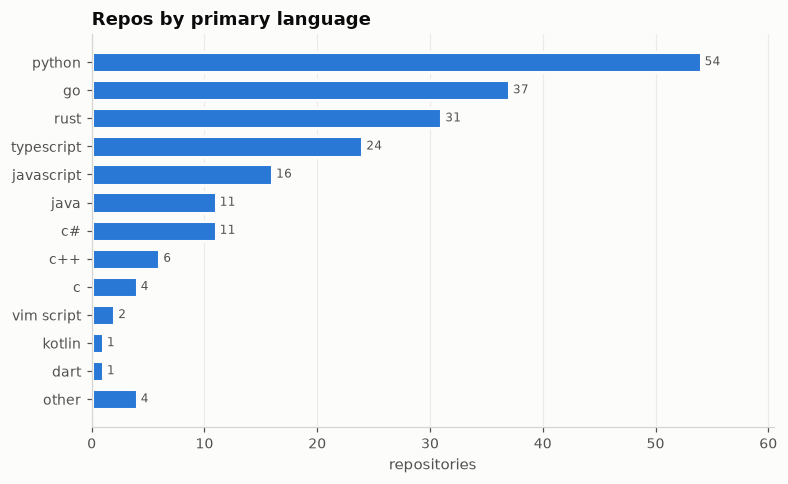

In [5]:
lang = repos.primary_language.replace("", "(none)").value_counts()
top = lang.head(12)
top["other"] = lang.iloc[12:].sum()
barh(top, "Repos by primary language", "repositories");

Median stars: 36,326 | min: 3,913


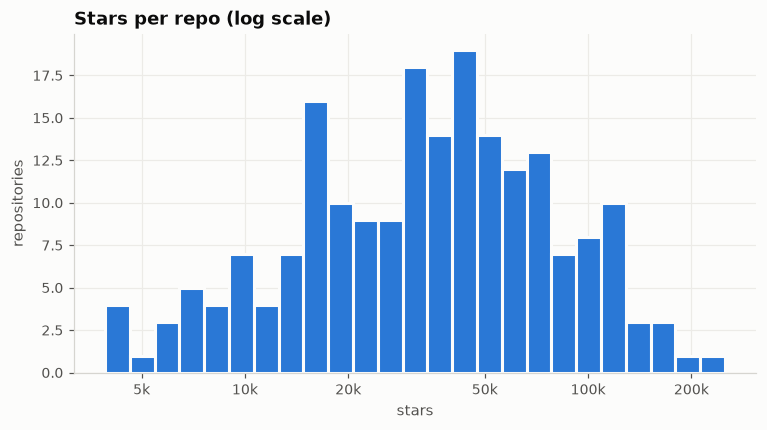

In [6]:
fig, ax = plt.subplots()
ax.hist(np.log10(repos.stars.clip(lower=1)), bins=25, color=BLUE, edgecolor=SURFACE, linewidth=2)
ticks = [5_000, 10_000, 20_000, 50_000, 100_000, 200_000]
ax.set_xticks(np.log10(ticks), [f"{t // 1000}k" for t in ticks])
ax.set_title("Stars per repo (log scale)"); ax.set_xlabel("stars"); ax.set_ylabel("repositories")
print("Median stars:", f"{repos.stars.median():,.0f}", "| min:", f"{repos.stars.min():,}")

Repos without topics: 9


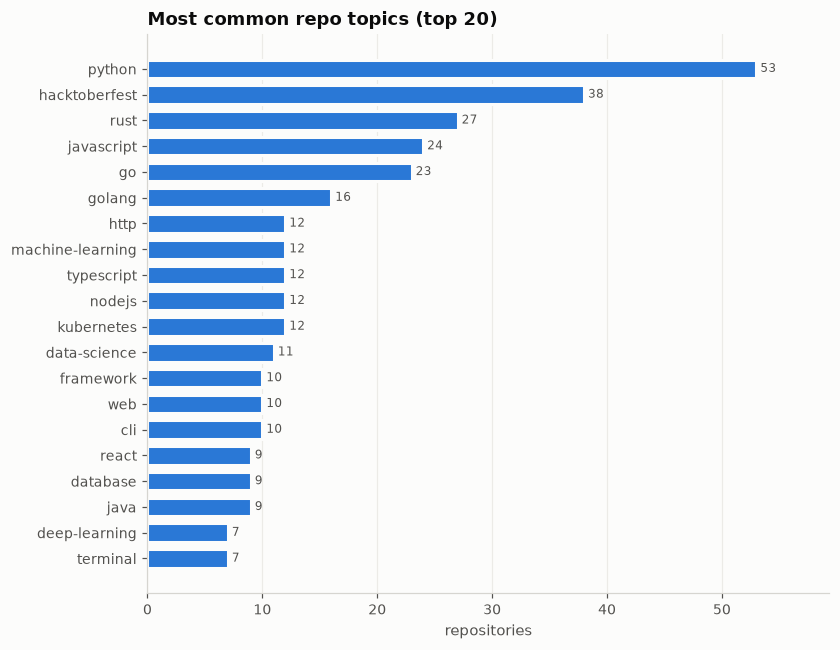

In [7]:
topics = Counter(t for ts in repos.topics for t in ts)
barh(pd.Series(dict(topics.most_common(20))), "Most common repo topics (top 20)", "repositories");
print("Repos without topics:", (repos.topics.map(len) == 0).sum())

## 3. Issues

Issues are the items we recommend. `final_text` (title + cleaned body) is what the NLP models read.

count    15053.0
mean       210.0
std        215.0
min          1.0
10%         38.0
50%        150.0
90%        451.0
99%        972.0
max       5107.0
Issues with empty body (title only): 0.7%
Issues longer than ~256 tokens (≈190 words, typical SBERT limit): 39.9%


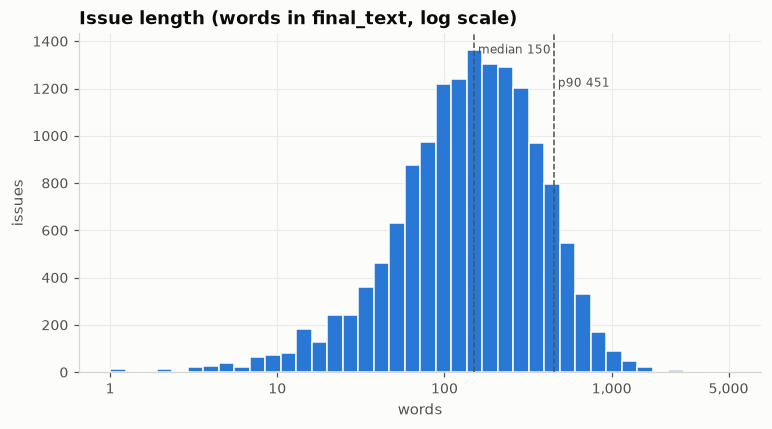

In [8]:
words = issues.final_text.str.split().str.len()
fig, ax = plt.subplots()
ax.hist(np.log10(words.clip(lower=1)), bins=40, color=BLUE, edgecolor=SURFACE, linewidth=1)
ticks = [1, 10, 100, 1_000, 5_000]
ax.set_xticks(np.log10(ticks), [f"{t:,}" for t in ticks])
for q, lab, y in [(0.5, "median", 0.97), (0.9, "p90", 0.87)]:
    v = words.quantile(q)
    ax.axvline(np.log10(v), color=INK_2, lw=1, ls="--")
    ax.text(np.log10(v), ax.get_ylim()[1] * y, f" {lab} {v:,.0f}", color=INK_2, fontsize=8, va="top")
ax.set_title("Issue length (words in final_text, log scale)"); ax.set_xlabel("words"); ax.set_ylabel("issues")
print(words.describe(percentiles=[.1, .5, .9, .99]).round(0).to_string())
print("Issues with empty body (title only):", pct((issues.body_clean == "").sum(), len(issues)))
print("Issues longer than ~256 tokens (≈190 words, typical SBERT limit):", pct((words > 190).sum(), len(issues)))

In [9]:
state = issues.assign(reason=issues.state_reason.replace("", "—")).groupby(["state", "reason"]).size()
state.rename("issues").to_frame().assign(share=lambda d: (d.issues / d.issues.sum() * 100).round(1))

issues  share
state  reason                    
closed completed      6062   40.3
       duplicate       257    1.7
       not_planned    1281    8.5
open   reopened        130    0.9
       —              7323   48.6

`not_planned` and `duplicate` issues were closed without being solved. For **recommendations** only
`open` issues are candidates; closed ones are still useful as training text and for labels.

Issues with no label: 27.2%
Distinct labels: 3154


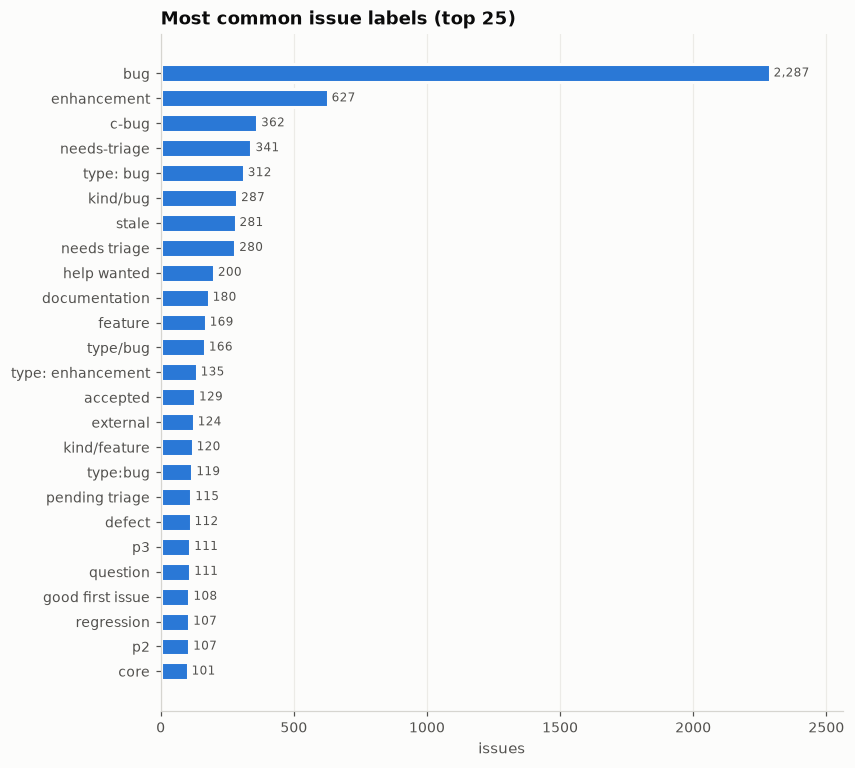

In [10]:
labels = Counter(l for ls in issues.labels for l in ls)
barh(pd.Series(dict(labels.most_common(25))), "Most common issue labels (top 25)", "issues");
print("Issues with no label:", pct((issues.labels.map(len) == 0).sum(), len(issues)))
print("Distinct labels:", len(labels))

In [11]:
bf = issues.is_beginner_friendly.map(lambda x: str(x) == "True")
hw = issues.is_help_wanted.map(lambda x: str(x) == "True")
is_open = issues.state == "open"
summary = pd.DataFrame({
    "all issues": [bf.sum(), hw.sum(), (bf | hw).sum()],
    "open issues": [(bf & is_open).sum(), (hw & is_open).sum(), ((bf | hw) & is_open).sum()],
}, index=["beginner-friendly", "help wanted", "either"])
summary["share of all"] = (summary["all issues"] / len(issues) * 100).round(1).astype(str) + "%"
summary

,all issues,open issues,share of all
beginner-friendly,210,110,1.4%
help wanted,226,131,1.5%
either,397,217,2.6%


Repos with at least one beginner/help-wanted issue: 80 of 202


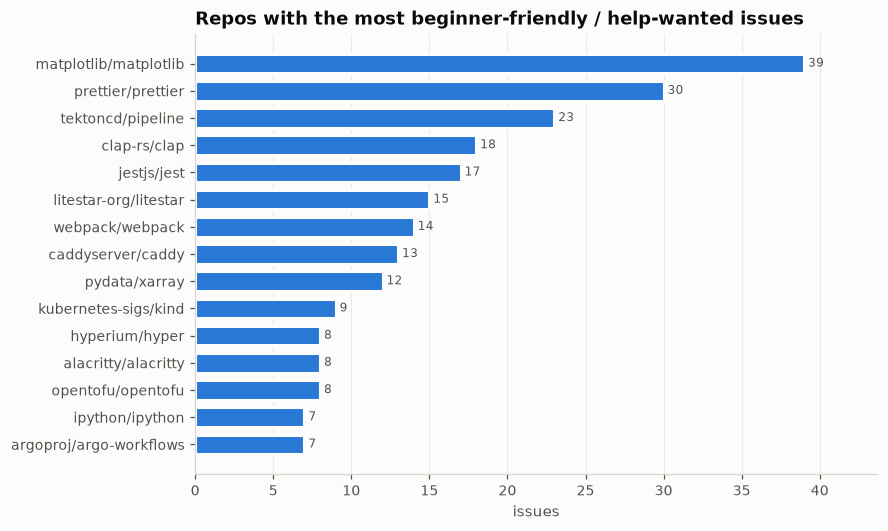

In [12]:
by_repo = issues.assign(bf=bf | hw).groupby("repo_id").bf.sum()
print("Repos with at least one beginner/help-wanted issue:", (by_repo > 0).sum(), "of", len(repos))
barh(by_repo.sort_values(ascending=False).head(15),
     "Repos with the most beginner-friendly / help-wanted issues", "issues");

In [13]:
lang_of = repos.set_index("repo_id").primary_language
iss_lang = issues.repo_id.map(lang_of).replace("", "(none)")
t = pd.DataFrame({"issues": iss_lang.value_counts(),
                  "beginner/help": iss_lang[bf | hw].value_counts()}).fillna(0).astype(int)
t["share %"] = (t["beginner/help"] / t.issues * 100).round(1)
t.index.name = "primary language"
t.sort_values("issues", ascending=False).head(12)

,issues,beginner/help,share %
primary language,,,
python,4021,114,2.8
go,2862,102,3.6
typescript,2091,35,1.7
rust,1931,80,4.1
javascript,1147,51,4.4
java,731,6,0.8
c#,663,1,0.2
c++,600,5,0.8
c,367,2,0.5


## 4. Is the data balanced across repos?

Collection capped issues at 100 and PRs at 50 per repo. Positive labels come from PRs, so check whether
a few repos dominate them.

Repos at the 100-issue cap: 101 | median issues/repo: 99


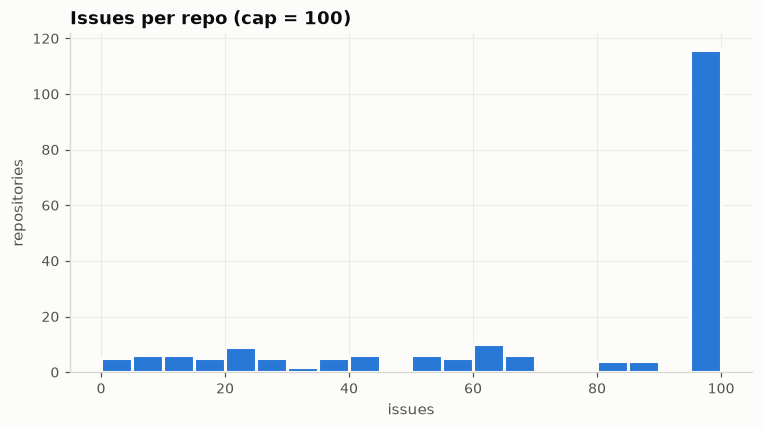

In [14]:
ipr = issues.repo_id.value_counts()
fig, ax = plt.subplots()
ax.hist(ipr, bins=range(0, 105, 5), color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.set_title("Issues per repo (cap = 100)"); ax.set_xlabel("issues"); ax.set_ylabel("repositories")
print("Repos at the 100-issue cap:", (ipr >= 100).sum(), "| median issues/repo:", int(ipr.median()))

Positive pairs: 1,822 from 163 repos (the other 39 repos have none)
Top 10 repos hold 18% of all positives


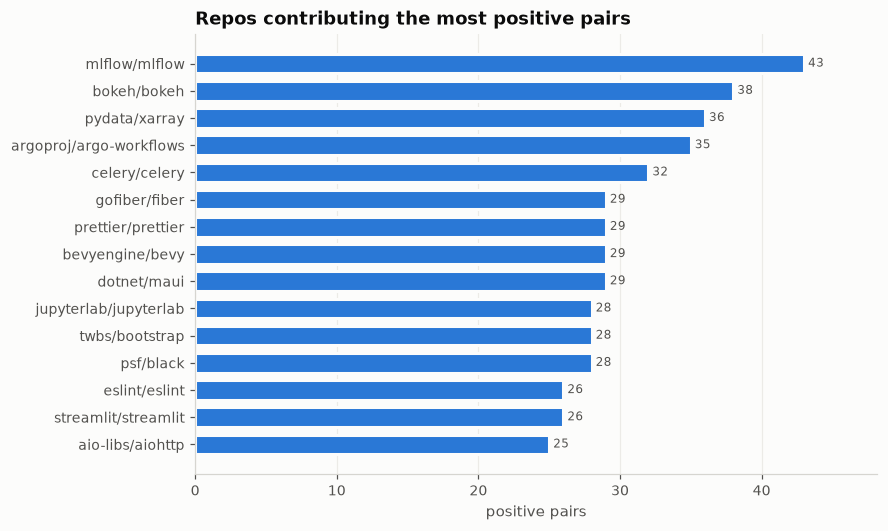

In [15]:
pos = pairs[pairs.label == 1]
pos_by_repo = pos.repo_id.value_counts()
share_top10 = pos_by_repo.head(10).sum() / len(pos)
print(f"Positive pairs: {len(pos):,} from {pos_by_repo.size} repos "
      f"(the other {len(repos) - pos_by_repo.size} repos have none)")
print(f"Top 10 repos hold {share_top10:.0%} of all positives")
barh(pos_by_repo.head(15), "Repos contributing the most positive pairs", "positive pairs");

50% of positives come from 37 repos (23% of repos with positives)


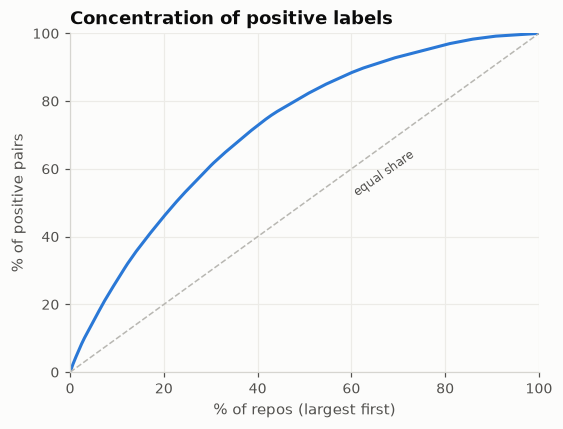

In [16]:
# cumulative share of positives vs. share of repos (how concentrated are labels?)
c = np.r_[0, pos_by_repo.sort_values(ascending=False).cumsum().values / len(pos)]
x = np.arange(len(c)) / pos_by_repo.size
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(x * 100, c * 100, color=BLUE, lw=2)
ax.plot([0, 100], [0, 100], color=GRAY, lw=1, ls="--")
ax.text(60, 52, "equal share", color=INK_2, fontsize=8, rotation=35)
ax.set_title("Concentration of positive labels"); ax.set_xlabel("% of repos (largest first)")
ax.set_ylabel("% of positive pairs")
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
half = np.argmax(c >= 0.5)
print(f"50% of positives come from {half} repos ({half / pos_by_repo.size:.0%} of repos with positives)")

## 5. Developers

Developer profiles are built from merged PRs. The fewer PRs a developer has, the thinner their
`experience_text` — the **cold-start** problem.

Developers contributing to more than one repo: 6.9%


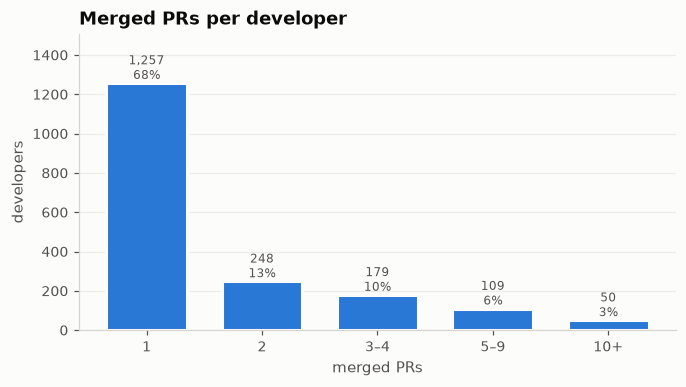

In [17]:
n = devs.merged_pr_count
bins = pd.cut(n, [0, 1, 2, 4, 9, np.inf], labels=["1", "2", "3–4", "5–9", "10+"])
dist = bins.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(dist.index.astype(str), dist.values, color=BLUE, width=0.7, edgecolor=SURFACE, linewidth=2)
for i, v in enumerate(dist.values):
    ax.text(i, v, f"{v:,}\n{v / len(devs):.0%}", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.grid(axis="x", visible=False); ax.margins(y=0.2)
ax.set_title("Merged PRs per developer"); ax.set_xlabel("merged PRs"); ax.set_ylabel("developers")
print("Developers contributing to more than one repo:", pct((devs.repo_count > 1).sum(), len(devs)))

experience_text words: {'count': 1843.0, 'mean': 57.0, 'std': 59.0, 'min': 12.0, '10%': 23.0, '50%': 42.0, '90%': 100.0, 'max': 947.0}


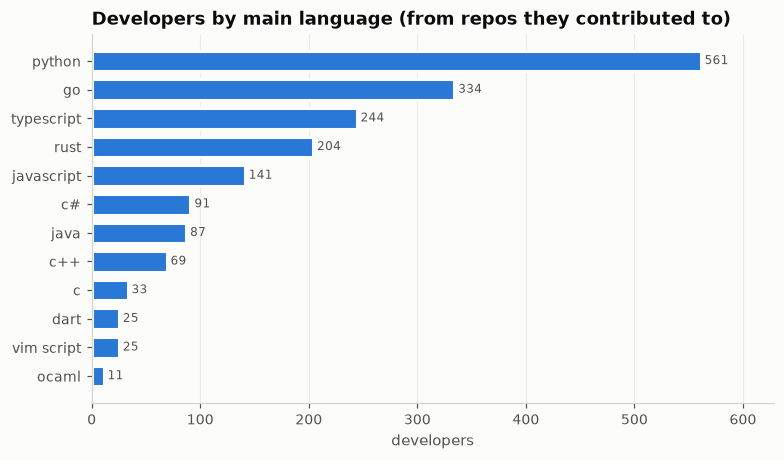

In [18]:
words_dev = devs.experience_text.str.split().str.len()
print("experience_text words:", words_dev.describe(percentiles=[.1, .5, .9]).round(0).to_dict())
dev_lang = Counter(l for ls in devs.languages for l in ls[:1])
barh(pd.Series(dict(dev_lang.most_common(12))), "Developers by main language (from repos they contributed to)",
     "developers");

In [19]:
assoc = prs.author_association.value_counts()
assoc.rename("merged PRs").to_frame().assign(share=lambda d: (d["merged PRs"] / len(prs) * 100).round(1))

,merged PRs,share
author_association,,
CONTRIBUTOR,2503,62.5
MEMBER,1088,27.2
COLLABORATOR,323,8.1
NONE,79,2.0
OWNER,10,0.2


`MEMBER` / `OWNER` / `COLLABORATOR` are maintainers. `CONTRIBUTOR` and `FIRST_TIME_CONTRIBUTOR` are
closer to our target users (outside contributors) — worth reporting results separately for them.

## 6. Labels and time — enough signal for the models?

The models are evaluated with a **chronological split** (older → train, newer → validation/test).
Check how positives spread over time and how many developers have more than one positive.

Suggested split (70 / 15 / 15 by time):
  train      < 2026-09-12
  validation < 2026-09-21
  test       ≥ 2026-09-21


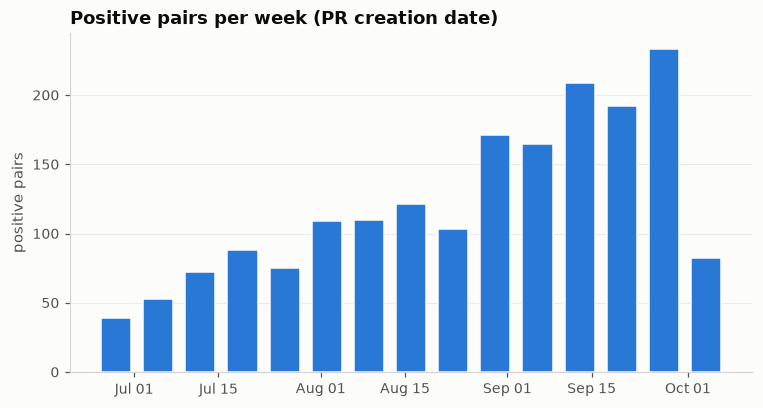

In [20]:
weekly = pos.set_index("event_time").resample("W").size()
weekly = weekly[weekly.index >= "2026-06-22"]
fig, ax = plt.subplots()
ax.bar(weekly.index, weekly.values, width=5, color=BLUE, edgecolor=SURFACE, linewidth=1)
ax.grid(axis="x", visible=False)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %d"))
ax.set_title("Positive pairs per week (PR creation date)"); ax.set_ylabel("positive pairs")
q = pos.event_time.quantile([0.7, 0.85])
print("Suggested split (70 / 15 / 15 by time):")
print("  train      <", q.iloc[0].date())
print("  validation <", q.iloc[1].date())
print("  test       ≥", q.iloc[1].date())

In [21]:
per_dev = pos.developer_id.value_counts()
t = pd.Series({
    "developers with ≥1 positive": per_dev.size,
    "… with ≥2 positives": (per_dev >= 2).sum(),
    "… with ≥3 positives": (per_dev >= 3).sum(),
    "developers with no positive (no linked issue in data)": len(devs) - per_dev.size,
})
t.rename("developers").to_frame()

,developers
developers with ≥1 positive,1042
… with ≥2 positives,287
… with ≥3 positives,141
developers with no positive (no linked issue in data),801


Developers with **≥ 2 positives** are the ones we can evaluate fairly with a chronological split:
the earlier positive builds the profile, the later one is the target.

In [22]:
# how many PRs link issues outside our issue sample (label coverage)
closes = prs.closes_issue_ids.map(len)
in_data = prs.closes_issue_ids_in_data.map(len)
print("PRs with a closing link:", pct((closes > 0).sum(), len(prs)))
print("… whose linked issue is in our data:", pct((in_data > 0).sum(), (closes > 0).sum()))
# For developers with ≥2 positives: is the later solved issue in a repo they had already worked in?
ordered = pos.sort_values("event_time")
seen, same, total = {}, 0, 0
for d, r in zip(ordered.developer_id, ordered.repo_id):
    if d in seen:
        total += 1; same += r in seen[d]
        seen[d].add(r)
    else:
        seen[d] = {r}
print(f"Later positives in a repo the developer had already solved an issue in: {pct(same, total)} ({same}/{total})")

PRs with a closing link: 97.8%
… whose linked issue is in our data: 46.5%
Later positives in a repo the developer had already solved an issue in: 86.7% (676/780)


## 7. Text — what do issues talk about?

A quick look at the vocabulary the TF-IDF baseline will see (simple tokenisation, English stopwords removed).

Vocabulary size (unique tokens): 88,304
Tokens appearing in ≥5 issues (rough TF-IDF vocab): 19,245


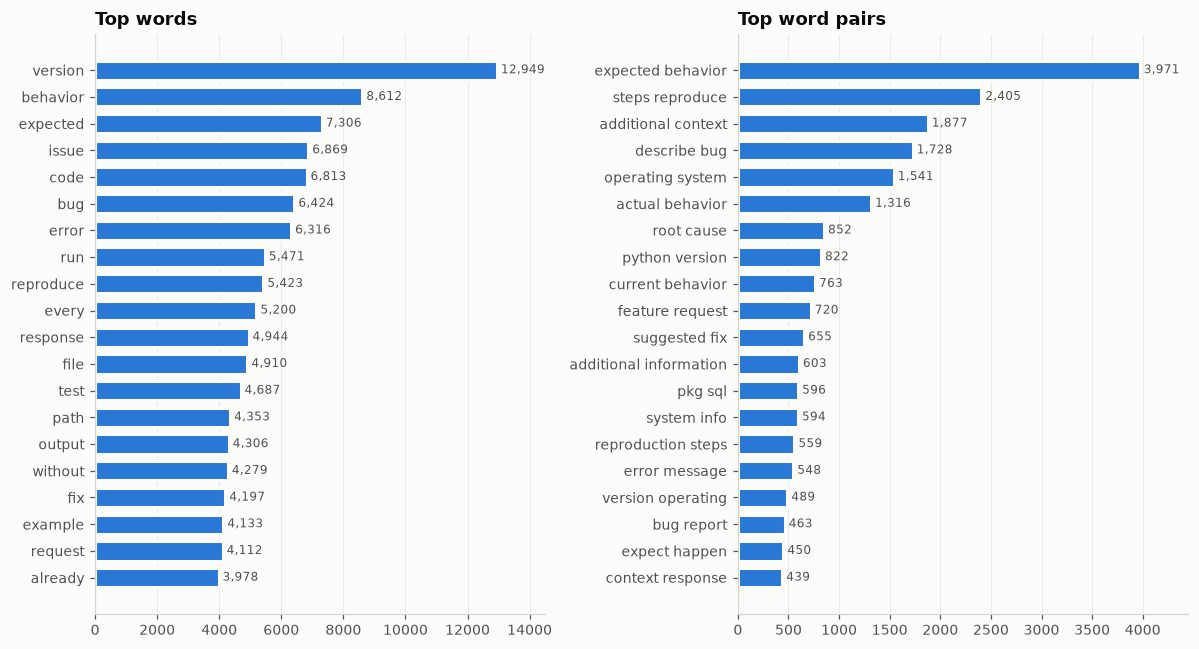

In [23]:
STOP = set("""a an the and or but if then else of to in on for with at by from as is are was were be been
being it its this that these those i we you he she they them our your my me us not no do does did done can
could should would will just so than too very also there here when what which who how why all any some such
into out up down over under again more most other only own same about after before while because each few
both between through during above below off once further nor have has had having get got use using used
need needs like want make work works see one two new now way may might must still even well""".split())

def tokens(text):
    return [w for w in re.findall(r"[a-z][a-z0-9+#.-]{1,}", text) if w not in STOP and not w.isdigit()]

uni = Counter(); bi = Counter()
for t in issues.final_text:
    tk = tokens(t)
    uni.update(tk); bi.update(zip(tk, tk[1:]))
print("Vocabulary size (unique tokens):", f"{len(uni):,}")
print("Tokens appearing in ≥5 issues (rough TF-IDF vocab):",
      f"{sum(1 for w, c in uni.items() if c >= 5):,}")
fig, axes = plt.subplots(1, 2, figsize=(11, 6))
barh(pd.Series(dict(uni.most_common(20))), "Top words", ax=axes[0])
barh(pd.Series({" ".join(k): v for k, v in bi.most_common(20)}), "Top word pairs", ax=axes[1])
plt.tight_layout()

The top words and word pairs are mostly **issue-template headings** ("expected behavior", "steps
to reproduce", "describe the bug", "additional context", "operating system"). They appear in almost every
bug report, so they say nothing about *what* an issue is about. TF-IDF will down-weight them
automatically (high document frequency, or set `max_df`), but for Sentence-BERT they dilute the
embedding — worth stripping common template headings before embedding.

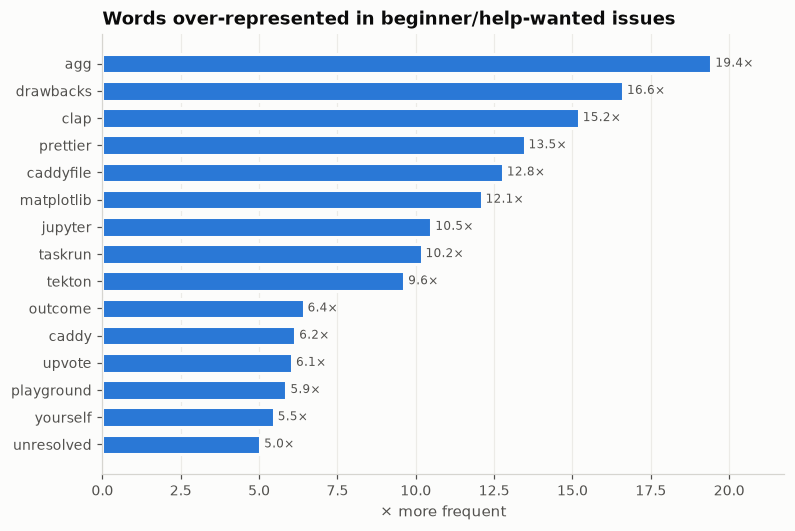

In [24]:
# Words that set beginner-friendly issues apart (ratio of relative frequencies)
def freq(texts):
    c = Counter(w for t in texts for w in set(tokens(t)))
    return c, len(texts)

cb, nb = freq(issues.final_text[bf | hw]); ca, na = freq(issues.final_text[~(bf | hw)])
score = {w: (cb[w] / nb) / ((ca[w] + 1) / na) for w in cb if cb[w] >= 8}
barh(pd.Series(score).sort_values(ascending=False).head(15),
     "Words over-represented in beginner/help-wanted issues", "× more frequent", fmt="{:.1f}×");

Most of these words are **project names** (agg, clap, prettier, caddyfile, matplotlib, jupyter,
tekton): beginner labels are concentrated in a few repos that label actively. So the label says more
about the *project's habits* than about the issue's difficulty. Treat `is_beginner_friendly` as a small
ranking boost, not a difficulty measure.

## 8. Key findings

Numbers are from the run on the 2026-10-01 dataset (202 repos).

**Coverage**
- 202 popular repos (median ~36k stars). Five languages cover 80%: Python 54, Go 37, Rust 31,
  TypeScript 24, JavaScript 16. Recommendations will be best for developers in these ecosystems and weak
  for Java/C#/C++ (11/11/6 repos). → **bias to report in Week 5.**
- 15,053 issues, 48.6% open. 76% were created inside the 3-month window; the rest are older issues
  with recent activity.
- 101 of 202 repos hit the 100-issue cap, so for big repos we only see the 100 most recently updated issues.

**Issue text**
- Median 150 words, p90 451. **40% are longer than ~190 words**, about what Sentence-BERT reads
  (256 tokens), so long issues get truncated: put the title first (already done) and consider
  removing template boilerplate.
- The most frequent phrases are issue-template headings ("expected behavior", "steps to reproduce").
  They carry no topic information.
- Only 0.7% of issues have an empty body.

**Labels**
- 27% of issues have no label and there are 3,154 distinct labels, so labelling is inconsistent across projects.
- Only **2.6% (397) are beginner-friendly or help wanted** (217 still open), spread over 80 repos and
  concentrated in projects that label actively. Use them as a small boost, not as the main signal.
- 10% of closed issues were `not_planned` or `duplicate`, so not every closed issue was solved.

**Developers (cold start)**
- 1,843 developers. **68% have exactly one merged PR**, and the median `experience_text` is 42 words.
  Most profiles are thin.
- Only 6.9% contributed to more than one repo.
- 62.5% of merged PRs come from `CONTRIBUTOR`s (outside contributors), the group closest to our
  target users.

**Labels for training/evaluation**
- 1,822 positive pairs from 163 repos, fairly spread out (top 10 repos = 18%; 50% from 37 repos).
- 46.5% of PRs that close an issue point to an issue we have. The rest point to older or uncollected
  issues; fetching them would roughly double the positives.
- **287 developers have ≥ 2 positives.** These are the ones we can evaluate chronologically
  (earlier positive → profile, later positive → target).
- **86.7% of later positives are in a repo where the developer had already solved an issue.**
  "Recommend open issues from repos you already contribute to" is therefore a very strong baseline.
  The TF-IDF/SBERT models must be compared against it, and evaluated separately on the harder
  cross-repo cases.
- Positives grow over time (newer PRs link to issues inside our window more often). The last week
  (Oct 1) is partial.
- Suggested chronological split by PR date (70/15/15): **train < 2026-09-12 ≤ validation < 2026-09-21 ≤ test**.

**Implications for Weeks 1–2**
1. Add two simple baselines next to TF-IDF/SBERT: *popularity* (most-commented open issues) and
   *same-repo* (open issues from repos the developer has contributed to).
2. Build developer profiles only from PRs before the split date (leakage).
3. Report metrics overall and for the cross-repo subset, and for `CONTRIBUTOR` vs maintainer accounts.
4. TF-IDF: use `max_df` (~0.5) to drop template words. SBERT: title + start of body; optionally
   strip template headings.